# VoltAhead – Cross-Model Comparison and Final Model Selection

## 1. Objective

This notebook compares the initial and optimized versions of
Logistic Regression, Random Forest, XGBoost, and LightGBM
against Persistence and Majority baselines.

All models are evaluated using the same validation dataset
and shared evaluation framework.

The primary selection metric is Class-0 Average Precision
(AP_0) on seen validation stations. Secondary metrics include
balanced accuracy, Class-0 precision, recall and F1-score,
ROC-AUC, Brier score, and computational efficiency.

The comparison uses previously exported validation predictions.
No model retraining is performed, and the test dataset remains
untouched during model selection.

## 2. Environment Setup and Imports

In [1]:
from pathlib import Path
import sys
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Locate the project root
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

# Import shared evaluation functions
from src.evaluation import (
    validate_prediction_output,
    evaluate_predictions,
    evaluate_by_horizon,
    evaluate_by_station_group,
)

# Define project directories
DATA_DIR = PROJECT_ROOT / "data" / "processed"
PREDICTION_DIR = PROJECT_ROOT / "outputs" / "predictions"
MODEL_DIR = PROJECT_ROOT / "outputs" / "models"
TABLE_DIR = PROJECT_ROOT / "outputs" / "tables"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"

pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 6)

print("Project root:", PROJECT_ROOT)
print("Prediction files:", len(list(PREDICTION_DIR.rglob("*.parquet"))))

Project root: /Users/nehiraydemir/VoltAhead
Prediction files: 12


## 3. Validation Dataset and Prediction Verification

All prediction files must contain the same validation
observations, target labels, and prediction horizons.

The shared evaluation framework is used to verify schema
consistency, observation coverage, probability ranges,
and classification thresholds before comparing models.

In [2]:
# Load the common validation dataset
validation = pd.read_parquet(DATA_DIR / "validation.parquet")

# Identify stations observed during training
training_station_ids = set(
    pd.read_parquet(
        DATA_DIR / "train.parquet",
        columns=["station_id"]
    )["station_id"].unique()
)

print("Validation observations:", len(validation))
print("Validation stations:", validation["station_id"].nunique())
print("Training stations:", len(training_station_ids))
print("Prediction horizons:", sorted(validation["prediction_horizon"].unique()))

validation.head()

Validation observations: 618726
Validation stations: 90
Training stations: 91
Prediction horizons: [np.int64(30), np.int64(40), np.int64(60)]


,station_id,time,target_time,hour,day_of_week,is_weekend,current_idle,current_busy,station_capacity,occupancy_rate,idle_lag_5,idle_lag_10,idle_lag_15,idle_lag_30,idle_lag_40,idle_lag_60,idle_lag_120,prediction_horizon,target
0,1703,2023-01-06,2023-01-06 00:30:00,0,4,0,2.0,0.0,2,0.000000,2.0,2.0,2.0,2.0,2.0,2.0,2.0,30,1.0
1,1703,2023-01-06,2023-01-06 00:40:00,0,4,0,2.0,0.0,2,0.000000,2.0,2.0,2.0,2.0,2.0,2.0,2.0,40,1.0
2,1703,2023-01-06,2023-01-06 01:00:00,0,4,0,2.0,0.0,2,0.000000,2.0,2.0,2.0,2.0,2.0,2.0,2.0,60,1.0
3,1712,2023-01-06,2023-01-06 00:30:00,0,4,0,4.0,2.0,6,0.333333,4.0,4.0,4.0,4.0,4.0,4.0,4.0,30,1.0
4,1712,2023-01-06,2023-01-06 00:40:00,0,4,0,4.0,2.0,6,0.333333,4.0,4.0,4.0,4.0,4.0,4.0,4.0,40,1.0


In [3]:
prediction_files = sorted(PREDICTION_DIR.rglob("*.parquet"))

assert len(prediction_files) == 12, "Expected 12 prediction files."

verification_results = []

for path in prediction_files:
    predictions = pd.read_parquet(path)

    # Validate against the common validation dataset
    validate_prediction_output(predictions, validation)

    verification_results.append({
        "file": path.name,
        "model_name": predictions["model_name"].iloc[0],
        "model_version": predictions["model_version"].iloc[0],
        "observations": len(predictions),
        "threshold": predictions["threshold"].iloc[0],
        "status": "Passed"
    })

verification_df = pd.DataFrame(verification_results)

display(verification_df)

print("Successfully verified:", len(verification_df), "/ 12")

,file,model_name,model_version,observations,threshold,status
0,majority_global_validation_predictions.parquet,majority,global,618726,0.500000,Passed
1,majority_horizon_validation_predictions.parquet,majority,horizon,618726,0.500000,Passed
2,persistence_deterministic_validation_predictio...,persistence,deterministic,618726,0.500000,Passed
3,persistence_probability_validation_predictions...,persistence,probability,618726,0.500000,Passed
4,lightgbm_initial_validation.parquet,lightgbm,initial,618726,0.500000,Passed
5,lightgbm_optimized_validation.parquet,lightgbm,optimized,618726,0.810000,Passed
6,logistic_regression_initial_validation.parquet,logistic_regression,initial,618726,0.500000,Passed
7,logistic_regression_optimized_validation.parquet,logistic_regression,optimized,618726,0.500000,Passed
8,initial_validation.parquet,random_forest,initial,618726,0.500000,Passed
9,optimized_sigmoid_validation.parquet,random_forest,optimized_sigmoid,618726,0.750952,Passed


Successfully verified: 12 / 12


### 3.1 Verification Findings

All 12 prediction files successfully passed the shared
validation checks.

Each file contains 618,726 validation observations with
consistent observation identifiers, target labels, prediction
horizons, and valid probability and threshold values.

Therefore, the exported predictions are suitable for
direct cross-model comparison without retraining.

## 4. Shared Model Evaluation

All model versions and baselines are evaluated using
the same evaluation functions.

The evaluation is performed at three levels:

- Overall validation performance
- Performance by prediction horizon (30, 40, and 60 minutes)
- Performance by station group (seen and unseen)

Class-0 Average Precision on seen validation stations
is the primary model selection metric.

In [4]:
overall_results = []
horizon_results = []
station_results = []

for path in prediction_files:
    predictions = pd.read_parquet(path)

    overall_results.append(
        evaluate_predictions(predictions, training_station_ids)
    )

    horizon_results.append(
        evaluate_by_horizon(predictions, training_station_ids)
    )

    station_results.append(
        evaluate_by_station_group(predictions, training_station_ids)
    )

    print(
        "Evaluated:",
        predictions["model_name"].iloc[0],
        predictions["model_version"].iloc[0]
    )

overall_df = pd.concat(overall_results, ignore_index=True)
horizon_df = pd.concat(horizon_results, ignore_index=True)
station_df = pd.concat(station_results, ignore_index=True)

print("\nOverall results:", overall_df.shape)
print("Horizon results:", horizon_df.shape)
print("Station group results:", station_df.shape)

Evaluated: majority global
Evaluated: majority horizon
Evaluated: persistence deterministic
Evaluated: persistence probability
Evaluated: lightgbm initial
Evaluated: lightgbm optimized
Evaluated: logistic_regression initial
Evaluated: logistic_regression optimized
Evaluated: random_forest initial
Evaluated: random_forest optimized_sigmoid
Evaluated: xgboost initial
Evaluated: xgboost optimized

Overall results: (12, 17)
Horizon results: (36, 18)
Station group results: (24, 17)


In [5]:
metric_columns = [
    "model_name",
    "model_version",
    "accuracy",
    "balanced_accuracy",
    "precision_0",
    "recall_0",
    "f1_0",
    "roc_auc",
    "ap_0",
    "brier_score"
]

overall_comparison = (
    overall_df[metric_columns]
    .sort_values("ap_0", ascending=False)
    .reset_index(drop=True)
)

display(overall_comparison)

,model_name,model_version,accuracy,balanced_accuracy,precision_0,recall_0,f1_0,roc_auc,ap_0,brier_score
0,random_forest,initial,0.996905,0.976736,0.970752,0.954726,0.962673,0.994443,0.979174,0.002751
1,random_forest,optimized_sigmoid,0.997060,0.979220,0.969612,0.959753,0.964657,0.993712,0.978323,0.002893
2,xgboost,initial,0.996761,0.976716,0.967258,0.954842,0.961010,0.994731,0.976265,0.002901
3,xgboost,optimized,0.996328,0.971868,0.966246,0.945177,0.955596,0.994323,0.975028,0.003254
4,lightgbm,optimized,0.996769,0.980473,0.960130,0.962691,0.961409,0.992737,0.972716,0.003620
5,logistic_regression,initial,0.993732,0.935812,0.974820,0.872608,0.920886,0.991961,0.966940,0.005097
6,lightgbm,initial,0.992174,0.917214,0.973640,0.835415,0.899247,0.994342,0.962936,0.005756
7,logistic_regression,optimized,0.995161,0.978728,0.926205,0.960796,0.943184,0.989880,0.953411,0.004520
8,persistence,probability,0.996732,0.980269,0.959633,0.962304,0.960967,0.982131,0.930455,0.003219
9,persistence,deterministic,0.996732,0.980269,0.959633,0.962304,0.960967,0.980269,0.925035,0.003268


In [9]:
seen_comparison = (
    station_df.loc[
        station_df["evaluation_group"] == "seen",
        metric_columns
    ]
    .sort_values("ap_0", ascending=False)
    .reset_index(drop=True)
)

display(seen_comparison)

,model_name,model_version,accuracy,balanced_accuracy,precision_0,recall_0,f1_0,roc_auc,ap_0,brier_score
0,random_forest,initial,0.996895,0.976951,0.970752,0.955170,0.962898,0.994732,0.979618,0.002755
1,random_forest,optimized_sigmoid,0.997052,0.979436,0.969612,0.960198,0.964882,0.993925,0.978766,0.002901
2,xgboost,initial,0.996750,0.976931,0.967258,0.955286,0.961235,0.994999,0.976696,0.002909
3,xgboost,optimized,0.996312,0.972080,0.966246,0.945616,0.955820,0.994502,0.975454,0.003265
4,lightgbm,optimized,0.996763,0.980691,0.960241,0.963138,0.961687,0.992975,0.973154,0.003634
5,logistic_regression,initial,0.993697,0.936012,0.974946,0.873013,0.921168,0.992346,0.967384,0.005125
6,lightgbm,initial,0.992119,0.917403,0.973640,0.835802,0.899471,0.994608,0.963382,0.005791
7,logistic_regression,optimized,0.995134,0.978935,0.926205,0.961242,0.943398,0.990250,0.953836,0.004544
8,persistence,probability,0.996740,0.980494,0.960077,0.962751,0.961412,0.982357,0.931308,0.003213
9,persistence,deterministic,0.996740,0.980494,0.960077,0.962751,0.961412,0.980494,0.925887,0.003260


In [10]:
unseen_comparison = (
    station_df.loc[
        station_df["evaluation_group"] == "unseen",
        metric_columns
    ]
    .sort_values("ap_0", ascending=False)
    .reset_index(drop=True)
)

display(unseen_comparison);

,model_name,model_version,accuracy,balanced_accuracy,precision_0,recall_0,f1_0,roc_auc,ap_0,brier_score
0,xgboost,optimized,0.997956,0.500000,NaN,0.0,0.0,0.732395,0.005077,0.002103
1,xgboost,initial,0.997956,0.500000,NaN,0.0,0.0,0.444397,0.003628,0.002114
2,lightgbm,initial,0.997956,0.500000,NaN,0.0,0.0,0.448969,0.003428,0.002104
3,random_forest,optimized_sigmoid,0.997956,0.500000,NaN,0.0,0.0,0.626863,0.003029,0.002041
4,lightgbm,optimized,0.997446,0.499744,0.0,0.0,0.0,0.534343,0.002603,0.002080
5,random_forest,initial,0.997956,0.500000,NaN,0.0,0.0,0.432260,0.002496,0.002316
6,majority,horizon,0.997956,0.500000,NaN,0.0,0.0,0.500341,0.002045,0.004166
7,majority,global,0.997956,0.500000,NaN,0.0,0.0,0.500000,0.002044,0.004166
8,persistence,deterministic,0.995913,0.498976,0.0,0.0,0.0,0.498976,0.002044,0.004087
9,logistic_regression,optimized,0.997956,0.500000,NaN,0.0,0.0,0.422355,0.002044,0.002088


### 4.1 Shared Evaluation Findings

Random Forest Initial achieves the highest Class-0 Average
Precision on both overall and seen validation observations.

Random Forest Optimized achieves the highest Class-0 F1-score,
while LightGBM Optimized achieves the highest balanced accuracy
and Class-0 recall.

All machine learning model versions outperform the Persistence
and Majority baselines in terms of Class-0 Average Precision.

However, all models fail to correctly identify unavailable
observations at the unseen validation station.

Since the unseen group contains only one station and 12
unavailable observations, reliable conclusions about
generalization to unseen stations cannot be drawn.

## 5. Initial vs. Optimized Model Comparison

The initial and optimized versions of each machine learning
model are compared using seen-validation performance.

The purpose is to determine whether optimization improves
the primary selection metric and to identify trade-offs
between ranking performance, classification performance,
and probability quality.

In [11]:
ml_models = [
    "logistic_regression",
    "random_forest",
    "xgboost",
    "lightgbm"
]

ml_seen = seen_comparison.loc[
    seen_comparison["model_name"].isin(ml_models)
].copy()

# Standardize version labels for comparison only
ml_seen["version_group"] = np.where(
    ml_seen["model_version"] == "initial",
    "initial",
    "optimized"
)

comparison_metrics = [
    "ap_0",
    "balanced_accuracy",
    "recall_0",
    "f1_0",
    "brier_score"
]

optimization_comparison = ml_seen.pivot(
    index="model_name",
    columns="version_group",
    values=comparison_metrics
)

for metric in comparison_metrics:
    optimization_comparison[(metric, "change")] = (
        optimization_comparison[(metric, "optimized")]
        - optimization_comparison[(metric, "initial")]
    )

optimization_comparison = optimization_comparison.reindex(
    columns=pd.MultiIndex.from_product([
        comparison_metrics,
        ["initial", "optimized", "change"]
    ])
)

display(optimization_comparison)

ap_0                     balanced_accuracy            \
                      initial optimized    change           initial optimized   
model_name                                                                      
lightgbm             0.963382  0.973154  0.009773          0.917403  0.980691   
logistic_regression  0.967384  0.953836 -0.013548          0.936012  0.978935   
random_forest        0.979618  0.978766 -0.000853          0.976951  0.979436   
xgboost              0.976696  0.975454 -0.001242          0.976931  0.972080   

                               recall_0                          f1_0  \
                       change   initial optimized    change   initial   
model_name                                                              
lightgbm             0.063288  0.835802  0.963138  0.127335  0.899471   
logistic_regression  0.042922  0.873013  0.961242  0.088230  0.921168   
random_forest        0.002485  0.955170  0.960198  0.005028  0.962898   
xgboost             -0.004850  0.955286  0.945616 -0.009670  0.961235   

                                        brier_score                      
                    optimized    change     initial optimized    change  
model_name                                                               
lightgbm             0.961687  0.062216    0.005791  0.003634 -0.002156  
logistic_regression  0.943398  0.022230    0.005125  0.004544 -0.000581  
random_forest        0.964882  0.001984    0.002755  0.002901  0.000146  
xgboost              0.955820 -0.005415    0.002909  0.003265  0.000356

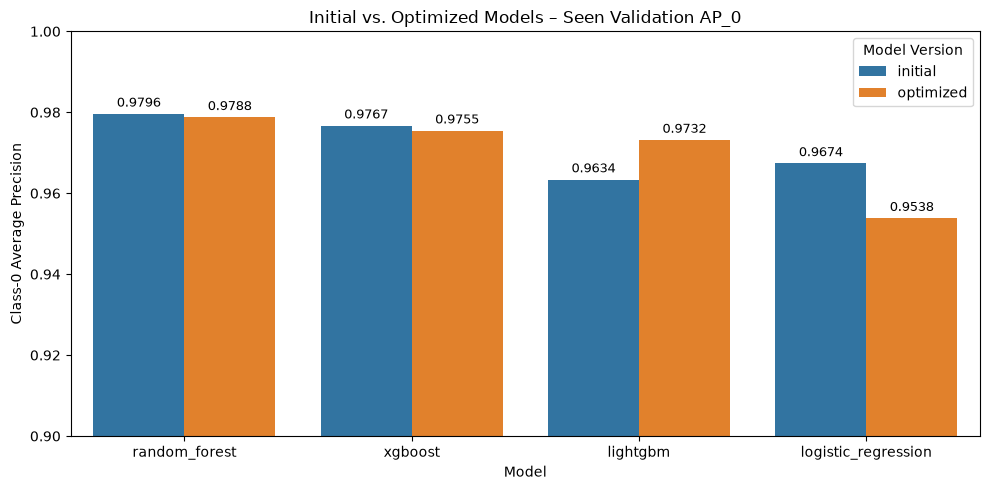

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=ml_seen,
    x="model_name",
    y="ap_0",
    hue="version_group",
    hue_order=["initial", "optimized"],
    ax=ax
)

ax.set_title("Initial vs. Optimized Models – Seen Validation AP_0")
ax.set_xlabel("Model")
ax.set_ylabel("Class-0 Average Precision")
ax.set_ylim(0.90, 1.0)

ax.legend(title="Model Version")

for container in ax.containers:
    ax.bar_label(container, fmt="%.4f", padding=3, fontsize=9)

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "model_comparison_initial_vs_optimized.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 5.1 Optimization Findings

LightGBM is the only model that improves across all five
compared metrics after optimization.

Random Forest shows a minor decrease in AP_0 while improving
recall, F1-score, and balanced accuracy.

Logistic Regression improves classification performance
and Brier score at the expense of ranking performance.

XGBoost shows a decrease in all five compared performance
metrics after optimization.

These results demonstrate that optimization does not
necessarily improve every evaluation metric. Model selection
must therefore consider the predefined primary metric
alongside secondary metrics and computational efficiency.

## 6. Prediction Horizon Comparison

This section evaluates model performance across the three
supported prediction horizons: 30, 40, and 60 minutes.

The objective is to examine how increasing the prediction
horizon affects the ability to identify unavailable
charging stations.

In [13]:
horizon_comparison = horizon_df.copy()

horizon_comparison["model_label"] = (
    horizon_comparison["model_name"]
    + " - "
    + horizon_comparison["model_version"]
)

horizon_ap_comparison = horizon_comparison.pivot(
    index="model_label",
    columns="prediction_horizon",
    values="ap_0"
)

horizon_ap_comparison["change_30_to_60"] = (
    horizon_ap_comparison[60]
    - horizon_ap_comparison[30]
)

horizon_ap_comparison = horizon_ap_comparison.sort_values(
    60, ascending=False
)

display(horizon_ap_comparison)

prediction_horizon,30,40,60,change_30_to_60
model_label,,,,
random_forest - initial,0.983383,0.980469,0.973665,-0.009717
random_forest - optimized_sigmoid,0.982423,0.979270,0.972892,-0.009531
xgboost - initial,0.982089,0.978398,0.968063,-0.014026
xgboost - optimized,0.980825,0.977153,0.966863,-0.013962
lightgbm - optimized,0.978269,0.974072,0.965608,-0.012661
logistic_regression - initial,0.972518,0.968269,0.960043,-0.012476
logistic_regression - optimized,0.960657,0.954999,0.944667,-0.015990
lightgbm - initial,0.975487,0.970805,0.941531,-0.033956
persistence - deterministic,0.939331,0.928002,0.907870,-0.031461


In [14]:
representative_models = (
    seen_comparison
    .sort_values("ap_0", ascending=False)
    .drop_duplicates(subset="model_name")
    .reset_index(drop=True)
)

representative_horizon = horizon_comparison.merge(
    representative_models[["model_name", "model_version"]],
    on=["model_name", "model_version"],
    how="inner"
)

display(
    representative_models[
        ["model_name", "model_version", "ap_0"]
    ]
)

,model_name,model_version,ap_0
0,random_forest,initial,0.979618
1,xgboost,initial,0.976696
2,lightgbm,optimized,0.973154
3,logistic_regression,initial,0.967384
4,persistence,probability,0.931308
5,majority,global,0.042185


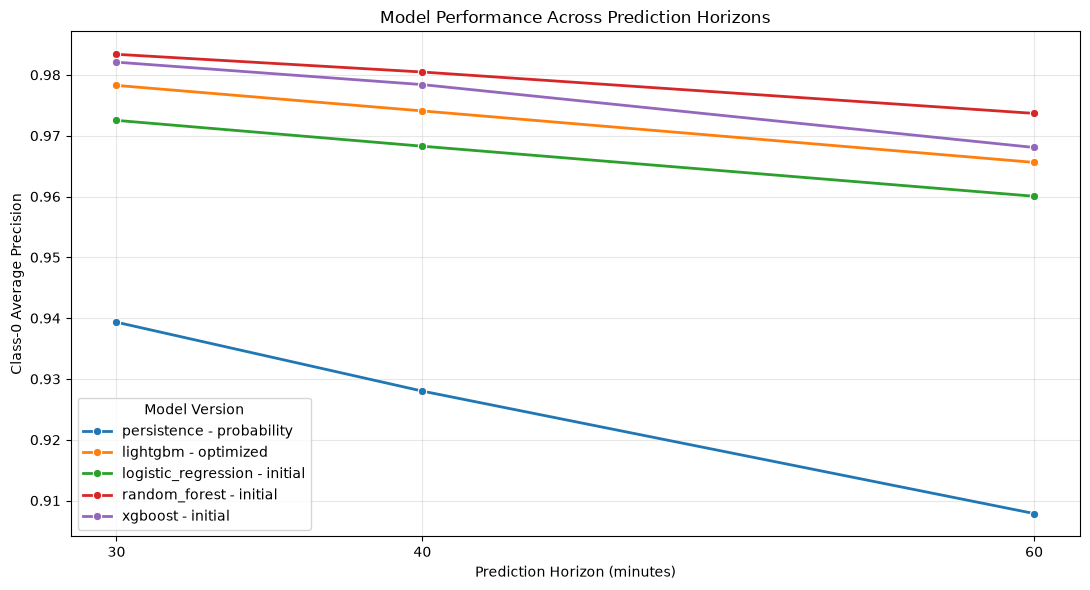

In [15]:
fig, ax = plt.subplots(figsize=(11, 6))

sns.lineplot(
    data=representative_horizon.loc[
        representative_horizon["model_name"] != "majority"
    ],
    x="prediction_horizon",
    y="ap_0",
    hue="model_label",
    marker="o",
    linewidth=2,
    ax=ax
)

ax.set_title("Model Performance Across Prediction Horizons")
ax.set_xlabel("Prediction Horizon (minutes)")
ax.set_ylabel("Class-0 Average Precision")
ax.set_xticks([30, 40, 60])

ax.legend(title="Model Version")
ax.grid(alpha=0.3)

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "model_comparison_by_horizon.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 6.1 Prediction Horizon Findings

All machine learning models and Persistence baselines
show decreasing AP_0 as the prediction horizon increases.

Random Forest Initial achieves the highest AP_0 across
all three prediction horizons.

The representative machine learning models experience
a smaller performance decrease than the Persistence
baseline between the 30-minute and 60-minute horizons.

LightGBM optimization substantially improves performance
at the 60-minute horizon.

These findings indicate that longer-term predictions are
more challenging and that machine learning models provide
additional predictive value beyond current station availability.

## 7. Precision-Recall and Calibration Analysis

The representative version of each model is compared
using Precision-Recall and calibration curves.

The analysis focuses on seen validation stations,
consistent with the primary model selection criterion.

Precision-Recall curves evaluate the ability to rank
unavailable observations, while calibration curves
evaluate the reliability of predicted availability
probabilities.

In [16]:
from sklearn.metrics import precision_recall_curve
from sklearn.calibration import calibration_curve

representative_keys = set(
    zip(
        representative_models["model_name"],
        representative_models["model_version"]
    )
)

representative_predictions = {}

for path in prediction_files:
    predictions = pd.read_parquet(path)

    key = (
        predictions["model_name"].iloc[0],
        predictions["model_version"].iloc[0]
    )

    if key in representative_keys:
        seen_predictions = predictions.loc[
            predictions["station_id"].isin(training_station_ids),
            ["y_true", "y_prob"]
        ].copy()

        representative_predictions[key] = seen_predictions

print("Representative models:", len(representative_predictions))

Representative models: 6


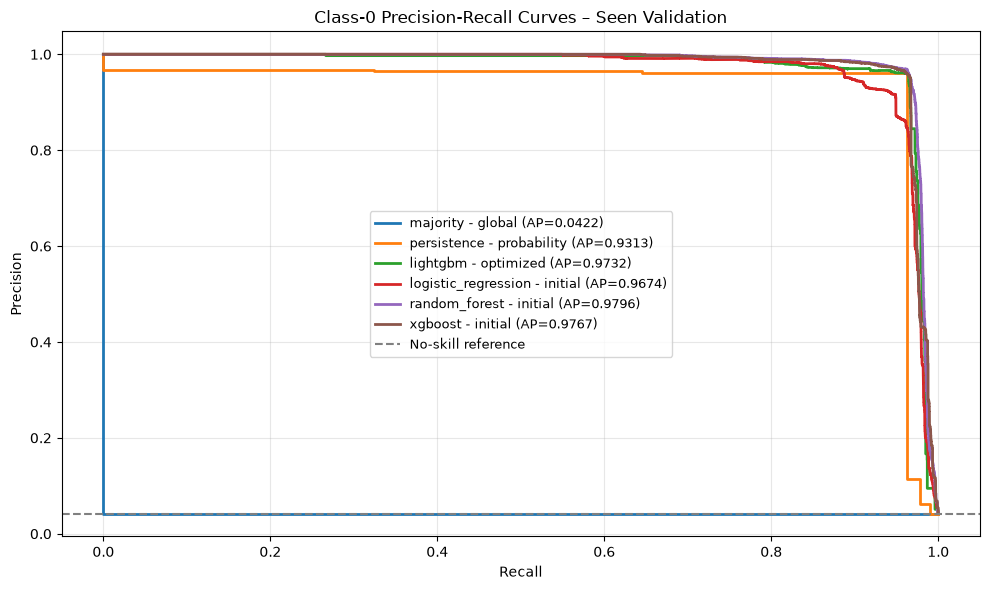

In [19]:
fig, ax = plt.subplots(figsize=(10, 6))

for (model_name, model_version), predictions in (
    representative_predictions.items()
):
    y_unavailable = (predictions["y_true"] == 0).astype(int)
    p_unavailable = 1 - predictions["y_prob"]

    precision, recall, _ = precision_recall_curve(
        y_unavailable,
        p_unavailable
    )

    ap = seen_comparison.loc[
        (seen_comparison["model_name"] == model_name)
        & (seen_comparison["model_version"] == model_version),
        "ap_0"
    ].iloc[0]

    ax.step(
    recall,
    precision,
    where="post",
    linewidth=2,
    label=f"{model_name} - {model_version} (AP={ap:.4f})"
)

# No-skill reference
prevalence = validation.loc[
    validation["station_id"].isin(training_station_ids),
    "target"
].eq(0).mean()

ax.axhline(
    prevalence,
    linestyle="--",
    color="gray",
    label="No-skill reference"
)

ax.set_title("Class-0 Precision-Recall Curves – Seen Validation")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "model_comparison_pr_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

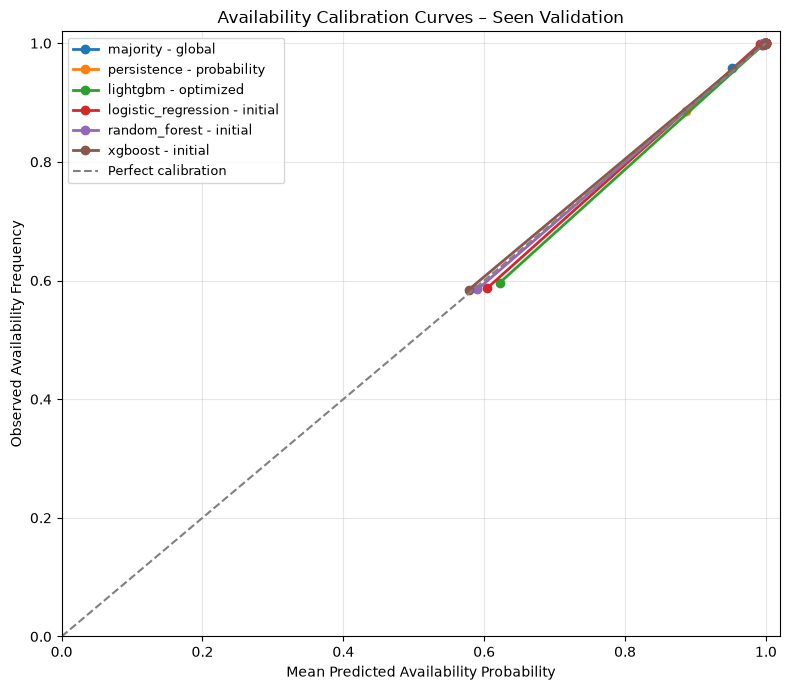

In [18]:
fig, ax = plt.subplots(figsize=(8, 7))

for (model_name, model_version), predictions in (
    representative_predictions.items()
):
    observed, predicted = calibration_curve(
        predictions["y_true"],
        predictions["y_prob"],
        n_bins=10,
        strategy="quantile"
    )

    ax.plot(
        predicted,
        observed,
        marker="o",
        linewidth=2,
        label=f"{model_name} - {model_version}"
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect calibration"
)

ax.set_title("Availability Calibration Curves – Seen Validation")
ax.set_xlabel("Mean Predicted Availability Probability")
ax.set_ylabel("Observed Availability Frequency")
ax.set_xlim(0, 1.02)
ax.set_ylim(0, 1.02)
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "model_comparison_calibration_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 8. Computational Efficiency Comparison

This section compares the computational requirements
of the initial and optimized machine learning models.

The comparison considers training time, inference time,
model artifact size, and available hardware information.

Reported execution times are interpreted with caution
because models may have been developed and evaluated
on different hardware and software environments.

In [20]:
metadata_files = sorted(TABLE_DIR.rglob("*.json"))

for path in metadata_files:
    print(path.name)

print("\nTotal JSON files:", len(metadata_files))

baselines_model_config.json
baselines_training_metadata.json
dataset_config.json
lightgbm_config.json
lightgbm_environment.json
lightgbm_initial_config.json
logistic_regression_artifact_manifest.json
logistic_regression_model_config.json
logistic_regression_training_metadata.json
random_forest_initial_metadata.json
random_forest_optimized_sigmoid_metadata.json
xgboost_artifact_manifest.json
xgboost_model_config.json
xgboost_training_metadata.json

Total JSON files: 14


In [21]:
for path in metadata_files:
    if "metadata" in path.name.lower():
        with path.open("r", encoding="utf-8") as f:
            metadata = json.load(f)

        print(f"\n{path.name}")
        print(list(metadata.keys()))


baselines_training_metadata.json
['environment', 'fit_rows', 'validation_rows', 'fit_time_seconds', 'inference_time_seconds_all_variants', 'validation_stations', 'unseen_validation_stations', 'test_data_used']

logistic_regression_training_metadata.json
['generated_at_utc', 'environment', 'training', 'model_artifacts', 'prediction_artifacts']

random_forest_initial_metadata.json
['model_name', 'model_version', 'dataset_version', 'training', 'validation', 'features', 'transformed_feature_count', 'hyperparameters', 'classification_threshold', 'optimization', 'model_complexity', 'environment', 'git_commit', 'git_working_tree_dirty']

random_forest_optimized_sigmoid_metadata.json
['model_name', 'model_version', 'dataset_version', 'features', 'n_features', 'hyperparameters', 'training_rows', 'calibration_rows', 'threshold_selection_rows', 'validation_rows', 'calibration_method', 'available_threshold', 'unavailable_threshold', 'base_training_time_seconds', 'validation_inference_time_seconds

In [26]:
efficiency_files = [
    "logistic_regression_training_metadata.json",
    "random_forest_initial_metadata.json",
    "random_forest_optimized_sigmoid_metadata.json",
    "xgboost_training_metadata.json",
    "lightgbm_initial_config.json",
    "lightgbm_config.json",
    "lightgbm_environment.json"
]

def print_efficiency_fields(data, prefix=""):
    for key, value in data.items():
        full_key = f"{prefix}.{key}" if prefix else key

        if isinstance(value, dict):
            print_efficiency_fields(value, full_key)

        elif any(term in full_key.lower() for term in [
            "second",
            "time",
            "throughput",
            "cpu",
            "processor",
            "ram",
            "thread",
            "n_jobs",
            "hardware"
        ]):
            print(f"{full_key}: {value}")


for filename in efficiency_files:
    with (TABLE_DIR / filename).open("r", encoding="utf-8") as f:
        metadata = json.load(f)

    print(f"\n--- {filename} ---")
    print_efficiency_fields(metadata)


--- logistic_regression_training_metadata.json ---
environment.processor: arm
environment.cpu_count: 10
environment.total_ram_gb: 16.0
training.initial_training_seconds: 2.4358223330345936
training.optimized_training_seconds: 2.053208417026326
training.initial_inference_seconds: 0.20287441700929776
training.optimized_inference_seconds: 0.14755033398978412

--- random_forest_initial_metadata.json ---
training.training_time_seconds: 46.56550770904869
validation.inference_time_seconds: 0.7766037499532104
hyperparameters.n_estimators: 100
hyperparameters.max_depth: 15
hyperparameters.min_samples_leaf: 5
hyperparameters.max_features: sqrt
hyperparameters.class_weight: None
hyperparameters.random_state: 42
hyperparameters.n_jobs: 4
environment.cpu_model: Apple M2 Pro
environment.cpu_architecture: arm64
environment.cpu_cores: 10
environment.ram_gb: 16.0
environment.n_jobs: 4

--- random_forest_optimized_sigmoid_metadata.json ---
hyperparameters.n_estimators: 100
hyperparameters.max_depth: 15

In [23]:
artifact_sizes = []

for path in sorted(MODEL_DIR.rglob("*")):
    if path.is_file() and path.suffix in [".joblib", ".json"]:
        if "manifest" not in path.name:
            artifact_sizes.append({
                "model_name": path.parent.name,
                "artifact": path.name,
                "size_kib": path.stat().st_size / 1024,
                "size_mib": path.stat().st_size / (1024 ** 2)
            })

artifact_sizes_df = pd.DataFrame(artifact_sizes)

display(artifact_sizes_df)

,model_name,artifact,size_kib,size_mib
0,lightgbm,lightgbm_initial.joblib,283.304688,0.276665
1,lightgbm,lightgbm_optimized.joblib,23.134766,0.022593
2,logistic_regression,logistic_regression_initial.joblib,5.211914,0.005090
3,logistic_regression,logistic_regression_optimized.joblib,5.787109,0.005651
4,random_forest,initial_model.joblib,3244.256836,3.168220
5,random_forest,optimized_sigmoid_model.joblib,3049.801758,2.978322
6,xgboost,xgboost_initial.joblib,312.909180,0.305575
7,xgboost,xgboost_initial_preprocessor.joblib,3.075195,0.003003
8,xgboost,xgboost_optimized.joblib,582.660156,0.569004
9,xgboost,xgboost_optimized_booster.json,878.273438,0.857689


In [27]:
for path in sorted(TABLE_DIR.glob("lightgbm*.csv")):
    print(path.name)

lightgbm_calibration_comparison.csv
lightgbm_efficiency_comparison.csv
lightgbm_feature_comparison.csv
lightgbm_horizon_comparison.csv
lightgbm_hyperparameter_results.csv
lightgbm_inference_compatibility.csv
lightgbm_initial_by_horizon.csv
lightgbm_initial_by_station_group.csv
lightgbm_initial_errors_by_hour.csv
lightgbm_initial_errors_by_prediction_horizon.csv
lightgbm_initial_errors_by_station_group.csv
lightgbm_initial_errors_by_station_id.csv
lightgbm_initial_feature_importance.csv
lightgbm_initial_overall.csv
lightgbm_model_selection.csv
lightgbm_optimized_by_horizon.csv
lightgbm_optimized_by_station_group.csv
lightgbm_optimized_overall.csv
lightgbm_overall_comparison.csv
lightgbm_reload_verification.csv
lightgbm_threshold_comparison.csv
lightgbm_threshold_search.csv


In [28]:
lightgbm_efficiency = pd.read_csv(
    TABLE_DIR / "lightgbm_efficiency_comparison.csv"
)

display(lightgbm_efficiency)

,metric,initial,optimized,change_percentage
0,training_observations,1.790062e+06,2.259325e+06,26.214902
1,feature_count,1.600000e+01,1.200000e+01,-25.000000
2,number_of_trees,2.000000e+02,1.300000e+01,-93.500000
3,training_time_seconds,1.980397e+01,2.232722e+00,-88.725885
4,training_input_memory_mib,1.604735e+02,1.594476e+02,-0.639322
5,validation_observations,6.187260e+05,6.187260e+05,0.000000
6,inference_time_seconds,3.184976e+00,2.913834e-01,-90.851317
7,predictions_per_second,1.942639e+05,2.123409e+06,993.053482
8,serialized_model_size_kib,2.833047e+02,2.313477e+01,-91.833963


In [29]:
efficiency_df = pd.DataFrame([
    ["logistic_regression", "initial", 2.435822, 0.202874, 5.211914, 10, 16.0, np.nan],
    ["logistic_regression", "optimized", 2.053208, 0.147550, 5.787109, 10, 16.0, np.nan],
    ["random_forest", "initial", 46.565508, 0.776604, 3244.256836, 10, 16.0, 4],
    ["random_forest", "optimized_sigmoid", 53.452840, 0.768309, 3049.801758, 10, 16.0, 4],
    ["xgboost", "initial", 25.20, 0.73, 312.909180, 2, 7.8, 2],
    ["xgboost", "optimized", 24.82, 0.75, 582.660156, 2, 7.8, 2],
    ["lightgbm", "initial", 19.803970, 3.184976, 283.304688, 12, 15.79, 4],
    ["lightgbm", "optimized", 2.232722, 0.2913834, 23.134766, 12, 15.79, 4]
], columns=[
    "model_name",
    "model_version",
    "training_time_seconds",
    "inference_time_seconds",
    "main_artifact_size_kib",
    "reported_cpu_count",
    "reported_ram_gb",
    "model_threads"
])

efficiency_df["predictions_per_second"] = (
    len(validation) / efficiency_df["inference_time_seconds"]
)

efficiency_df = efficiency_df.merge(
    ml_seen[["model_name", "model_version", "ap_0"]],
    on=["model_name", "model_version"],
    how="left"
)

efficiency_df = efficiency_df.sort_values(
    "ap_0", ascending=False
).reset_index(drop=True)

display(efficiency_df)

,model_name,model_version,training_time_seconds,inference_time_seconds,main_artifact_size_kib,reported_cpu_count,reported_ram_gb,model_threads,predictions_per_second,ap_0
0,random_forest,initial,46.565508,0.776604,3244.256836,10,16.00,4.0,7.967072e+05,0.979618
1,random_forest,optimized_sigmoid,53.452840,0.768309,3049.801758,10,16.00,4.0,8.053088e+05,0.978766
2,xgboost,initial,25.200000,0.730000,312.909180,2,7.80,2.0,8.475699e+05,0.976696
3,xgboost,optimized,24.820000,0.750000,582.660156,2,7.80,2.0,8.249680e+05,0.975454
4,lightgbm,optimized,2.232722,0.291383,23.134766,12,15.79,4.0,2.123409e+06,0.973154
5,logistic_regression,initial,2.435822,0.202874,5.211914,10,16.00,NaN,3.049804e+06,0.967384
6,lightgbm,initial,19.803970,3.184976,283.304688,12,15.79,4.0,1.942639e+05,0.963382
7,logistic_regression,optimized,2.053208,0.147550,5.787109,10,16.00,NaN,4.193331e+06,0.953836


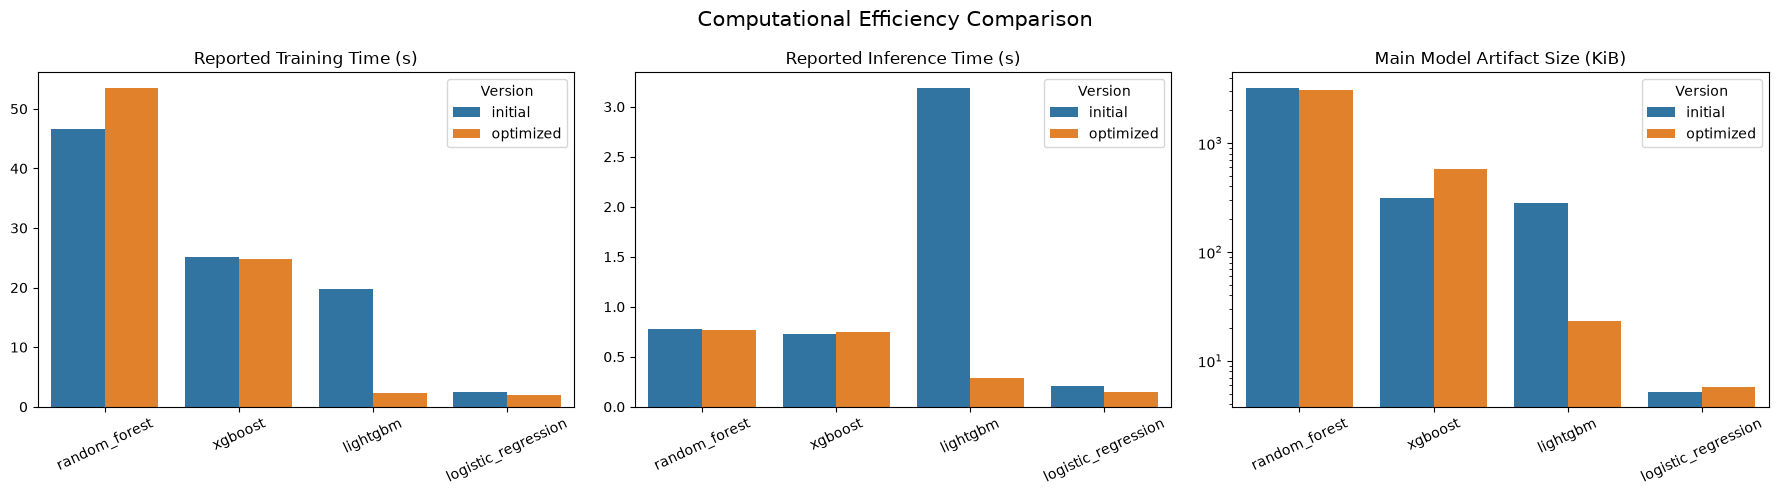

In [30]:
efficiency_plot = efficiency_df.copy()

efficiency_plot["version_group"] = np.where(
    efficiency_plot["model_version"] == "initial",
    "initial",
    "optimized"
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

metrics = [
    ("training_time_seconds", "Reported Training Time (s)"),
    ("inference_time_seconds", "Reported Inference Time (s)"),
    ("main_artifact_size_kib", "Main Model Artifact Size (KiB)")
]

for ax, (metric, title) in zip(axes, metrics):
    sns.barplot(
        data=efficiency_plot,
        x="model_name",
        y=metric,
        hue="version_group",
        hue_order=["initial", "optimized"],
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=25)
    ax.legend(title="Version")

# Logarithmic scale for large artifact size differences
axes[2].set_yscale("log")

fig.suptitle(
    "Computational Efficiency Comparison",
    fontsize=15
)

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "model_comparison_efficiency.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 8.3 Computational Efficiency Findings

LightGBM demonstrates the most substantial efficiency
improvement after optimization, reducing reported training
time by 88.73%, inference time by 90.85%, and serialized
model size by 91.83%.

Logistic Regression has the smallest main model artifacts
and the lowest reported inference times.

Random Forest achieves the highest AP_0 but requires
larger serialized model artifacts.

XGBoost optimization increases the main model artifact
size without improving the primary evaluation metric.

Execution times were recorded on different hardware and
software environments. Training times may also exclude
different optimization and calibration stages.

Therefore, these results represent reported computational
costs rather than a controlled cross-model benchmark.

Artifact sizes refer to the main serialized joblib files
and exclude supplementary preprocessing files and
alternative serialization formats.

## 9. Final Model Selection

Model selection is based primarily on Class-0 Average
Precision on seen validation stations.

Secondary considerations include classification performance,
probability quality, prediction horizon robustness, and
computational efficiency.

Two rankings are presented:

- Ranking of optimized model versions only.
- Ranking of the best-performing version of each model.

The test dataset is not used during model selection.

In [31]:
selection_columns = [
    "model_name",
    "model_version",
    "ap_0",
    "balanced_accuracy",
    "precision_0",
    "recall_0",
    "f1_0",
    "brier_score"
]

# Ranking of optimized models only
optimized_ranking = (
    ml_seen.loc[
        ml_seen["version_group"] == "optimized",
        selection_columns
    ]
    .sort_values("ap_0", ascending=False)
    .reset_index(drop=True)
)

# Ranking of the best version of each model
best_version_ranking = (
    ml_seen
    .sort_values("ap_0", ascending=False)
    .drop_duplicates(subset="model_name")
    [selection_columns]
    .reset_index(drop=True)
)

optimized_ranking.index += 1
best_version_ranking.index += 1

print("Optimized Model Ranking")
display(optimized_ranking)

print("Best Version Ranking")
display(best_version_ranking)

Optimized Model Ranking


,model_name,model_version,ap_0,balanced_accuracy,precision_0,recall_0,f1_0,brier_score
1,random_forest,optimized_sigmoid,0.978766,0.979436,0.969612,0.960198,0.964882,0.002901
2,xgboost,optimized,0.975454,0.972080,0.966246,0.945616,0.955820,0.003265
3,lightgbm,optimized,0.973154,0.980691,0.960241,0.963138,0.961687,0.003634
4,logistic_regression,optimized,0.953836,0.978935,0.926205,0.961242,0.943398,0.004544


Best Version Ranking


,model_name,model_version,ap_0,balanced_accuracy,precision_0,recall_0,f1_0,brier_score
1,random_forest,initial,0.979618,0.976951,0.970752,0.955170,0.962898,0.002755
2,xgboost,initial,0.976696,0.976931,0.967258,0.955286,0.961235,0.002909
3,lightgbm,optimized,0.973154,0.980691,0.960241,0.963138,0.961687,0.003634
4,logistic_regression,initial,0.967384,0.936012,0.974946,0.873013,0.921168,0.005125


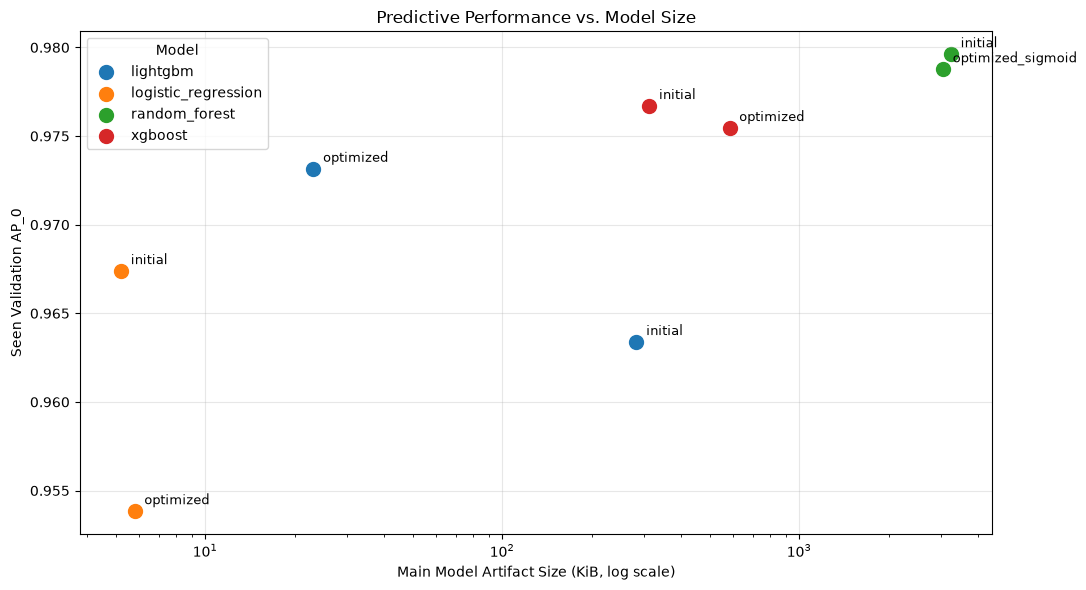

In [32]:
fig, ax = plt.subplots(figsize=(11, 6))

for model_name, group in efficiency_df.groupby("model_name"):
    ax.scatter(
        group["main_artifact_size_kib"],
        group["ap_0"],
        s=100,
        label=model_name
    )

    for _, row in group.iterrows():
        ax.annotate(
            row["model_version"],
            (row["main_artifact_size_kib"], row["ap_0"]),
            xytext=(7, 5),
            textcoords="offset points",
            fontsize=9
        )

ax.set_xscale("log")
ax.set_xlabel("Main Model Artifact Size (KiB, log scale)")
ax.set_ylabel("Seen Validation AP_0")
ax.set_title("Predictive Performance vs. Model Size")
ax.legend(title="Model")
ax.grid(alpha=0.3)

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "model_comparison_performance_vs_size.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 9.1 Model Selection Findings

Random Forest ranks first under both selection policies.

Random Forest Initial achieves the highest seen-validation
AP_0 of 0.979618, while Random Forest Optimized achieves
the highest AP_0 among optimized models at 0.978766.

Random Forest Initial also achieves the lowest Brier score
and the highest AP_0 across all three prediction horizons.

Random Forest Optimized provides slightly better
classification performance, particularly in terms of
Class-0 recall and F1-score.

LightGBM Optimized represents a strong alternative when
computational efficiency and model size are prioritized.

Based on the predefined primary evaluation metric,
Random Forest Initial is the recommended candidate if
initial model versions are eligible for final selection.

If selection is restricted to optimized versions,
Random Forest Optimized is the highest-ranked candidate.

The final model version is subject to team approval.
The test dataset remains unused.

## 10. Export Comparison Results

All cross-model evaluation tables, optimization results,
computational efficiency measurements, and candidate
rankings are exported for reproducibility, documentation,
and subsequent system integration.

In [33]:
comparison_tables = {
    "verification": verification_df,
    "overall": overall_df,
    "by_horizon": horizon_df,
    "by_station_group": station_df,
    "seen": seen_comparison,
    "unseen": unseen_comparison,
    "initial_vs_optimized": optimization_comparison,
    "horizon_ap": horizon_ap_comparison,
    "efficiency": efficiency_df,
    "optimized_ranking": optimized_ranking,
    "best_version_ranking": best_version_ranking
}

TABLE_DIR.mkdir(parents=True, exist_ok=True)

for name, table in comparison_tables.items():
    path = TABLE_DIR / f"model_comparison_{name}.csv"

    table.to_csv(
        path,
        index=name in [
            "initial_vs_optimized",
            "horizon_ap",
            "optimized_ranking",
            "best_version_ranking"
        ],
        na_rep="N/A"
    )

    print("Saved:", path.name)

print("\nTotal exported tables:", len(comparison_tables))

Saved: model_comparison_verification.csv
Saved: model_comparison_overall.csv
Saved: model_comparison_by_horizon.csv
Saved: model_comparison_by_station_group.csv
Saved: model_comparison_seen.csv
Saved: model_comparison_unseen.csv
Saved: model_comparison_initial_vs_optimized.csv
Saved: model_comparison_horizon_ap.csv
Saved: model_comparison_efficiency.csv
Saved: model_comparison_optimized_ranking.csv
Saved: model_comparison_best_version_ranking.csv

Total exported tables: 11


In [34]:
exported_tables = sorted(
    TABLE_DIR.glob("model_comparison_*.csv")
)

exported_figures = sorted(
    FIGURE_DIR.glob("model_comparison_*.png")
)

print("Comparison tables:", len(exported_tables))
print("Comparison figures:", len(exported_figures))

print("\nFigures:")
for path in exported_figures:
    print(path.name)

Comparison tables: 11
Comparison figures: 6

Figures:
model_comparison_by_horizon.png
model_comparison_calibration_curves.png
model_comparison_efficiency.png
model_comparison_initial_vs_optimized.png
model_comparison_performance_vs_size.png
model_comparison_pr_curves.png


## 11. Conclusion

This notebook compared eight machine learning model versions
and four baseline variants using a common validation dataset
of 618,726 observations.

All prediction artifacts successfully passed the shared
validation checks, ensuring consistent evaluation across
models.

Random Forest Initial achieved the highest seen-validation
Class-0 Average Precision of 0.979618 and the lowest Brier
score of 0.002755.

Random Forest Optimized ranked first among optimized models
and achieved the highest Class-0 F1-score.

LightGBM Optimized demonstrated the strongest improvement
in computational efficiency while maintaining competitive
predictive performance.

All machine learning model versions outperformed the
Persistence and Majority baselines in terms of AP_0.

Performance generally decreased as the prediction horizon
increased. Random Forest Initial maintained the highest
AP_0 across all three prediction horizons.

Generalization to unseen stations remains a limitation.
None of the evaluated models correctly identified the
12 unavailable observations at the unseen validation station.

Random Forest is the highest-ranked model family under
both selection policies. The final model version will be
confirmed through team agreement before test evaluation
and system integration.

The test dataset was not used during this comparison.